# Лабораторная работа № 1. Генератор синтетических временных рядов

**Тема:** Разработка генератора синтетических временных рядов на Python в Jupyter Notebook.

**Цель:** создать временной ряд с шагом 5 минут, настраиваемыми количеством точек, изменением разброса значений, трендом и сезонностью. Сохранить данные в CSV, а графики - в PNG.

Используем `numpy` и `matplotlib`, без `pandas`. Все ячейки можно последовательно запускать в Jupyter Notebook или Google Colab.

## 1. Подключение библиотек

`datetime` отвечает за даты, `csv` - за сохранение таблицы, `pathlib` - за создание папки. Это стандартная библиотека Python.

In [1]:
from datetime import datetime, timedelta
from pathlib import Path
import csv
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.dates import DateFormatter, AutoDateLocator

OUTPUT_DIR = Path(".")
IMAGE_DIR = OUTPUT_DIR / "images"
IMAGE_DIR.mkdir(parents=True, exist_ok=True)


## 2. Функция генерации

Каждое значение ряда вычисляется как **базовый уровень + тренд + сезонная составляющая + случайный шум**. Шум имеет нормальное распределение с нулевым средним.

- `volatility`: `const`, `grow`, `decay` или `random`
- `trend`: `none`, `fast_up`, `slow_up`, `fast_down`, `slow_down` или `random`
- `seasonality`: `none`, `one`, `two` или `random`

При выборе `random` режим выбирается случайно из доступных. Шаг всегда равен пяти минутам, отсчёт начинается с 00:00 текущего дня. Значение `seed` позволяет повторить пример с тем же случайным шумом.

In [2]:
def generate_time_series(n_points=1000, volatility="random", trend="random",
                         seasonality="random", seed=None):
    """Возвращает метки времени, значения ряда и выбранные режимы."""
    if not isinstance(n_points, (int, np.integer)) or isinstance(n_points, (bool, np.bool_)) or n_points <= 0:
        raise ValueError("n_points должно быть положительным целым числом")

    volatility_modes = ("const", "grow", "decay")
    trend_modes = ("none", "fast_up", "slow_up", "fast_down", "slow_down")
    seasonality_modes = ("none", "one", "two")

    for label, option, modes in (
        ("volatility", volatility, volatility_modes),
        ("trend", trend, trend_modes),
        ("seasonality", seasonality, seasonality_modes),
    ):
        if option not in (*modes, "random"):
            raise ValueError(f"Недопустимое значение {label}: {option}. Допустимые: {(*modes, 'random')}")

    rng = np.random.default_rng(seed)
    if volatility == "random":
        volatility = str(rng.choice(volatility_modes))
    if trend == "random":
        trend = str(rng.choice(trend_modes))
    if seasonality == "random":
        seasonality = str(rng.choice(seasonality_modes))

    start_time = datetime.now().replace(hour=0, minute=0, second=0, microsecond=0)
    timestamps = [start_time + timedelta(minutes=5 * i) for i in range(n_points)]

    t = np.arange(n_points)
    position = t / max(n_points - 1, 1)  # от 0 до 1 на протяжении ряда

    # Тренд: изменения за весь наблюдаемый отрезок.
    total_changes = {"none": 0, "fast_up": 35, "slow_up": 10,
                     "fast_down": -35, "slow_down": -10}
    trend_values = total_changes[trend] * position

    # Сезонность: периоды 12 точек (1 час) и 72 точки (6 часов).
    seasonal_values = np.zeros(n_points)
    if seasonality in ("one", "two"):
        seasonal_values += 7 * np.sin(2 * np.pi * t / 12)
    if seasonality == "two":
        seasonal_values += 4 * np.sin(2 * np.pi * t / 72)

    # Стандартное отклонение задаёт силу шума; дисперсия равна его квадрату.
    if volatility == "const":
        sigma = np.full(n_points, 2.0)
    elif volatility == "grow":
        sigma = 1.0 + 6.0 * position
    else:  # decay
        sigma = 7.0 - 6.0 * position

    noise = rng.normal(loc=0.0, scale=sigma, size=n_points)
    values = 100.0 + trend_values + seasonal_values + noise
    modes = {"volatility": volatility, "trend": trend, "seasonality": seasonality}
    return timestamps, values, modes


## 3. Сохранение и построение графиков

CSV имеет два столбца: `timestamp,value`. Название CSV формируется по времени сохранения. При совпадении названий добавляется числовой суффикс, чтобы не перезаписать старый файл. Графики сохраняются в папке `images`.

In [3]:
def save_csv(timestamps, values, directory=OUTPUT_DIR):
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    basename = "ts_" + datetime.now().strftime("%Y%m%d_%H%M%S")
    path = directory / f"{basename}.csv"
    suffix = 1
    while path.exists():
        path = directory / f"{basename}_{suffix}.csv"
        suffix += 1

    with path.open("w", encoding="utf-8", newline="") as file:
        writer = csv.writer(file)
        writer.writerow(["timestamp", "value"])
        for timestamp, value in zip(timestamps, values):
            writer.writerow([timestamp.strftime("%Y-%m-%d %H:%M:%S"), f"{value:.6f}"])
    return path


def plot_time_series(timestamps, values, title, image_path=None):
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(timestamps, values, color="mediumpurple", linewidth=1.2)
    ax.set_title(title)
    ax.set_xlabel("Дата и время")
    ax.set_ylabel("Значение")
    ax.grid(True, alpha=0.3)
    ax.xaxis.set_major_locator(AutoDateLocator())
    ax.xaxis.set_major_formatter(DateFormatter("%d.%m %H:%M"))
    fig.autofmt_xdate()
    fig.tight_layout()
    if image_path is not None:
        fig.savefig(image_path, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)


## 4. Демонстрация случайной генерации

Вызываем генератор с параметрами по умолчанию: **1000 точек**, а три режима выбираются случайно. Выводим реальные выбранные параметры, первые три строки и сохраняем CSV.

Количество точек: 1000
Выбранные режимы: {'volatility': 'const', 'trend': 'none', 'seasonality': 'none'}
2026-10-09 00:00:00 103.796815
2026-10-09 00:05:00 100.380561
2026-10-09 00:10:00 98.669436
CSV: ts_20261009_083135.csv


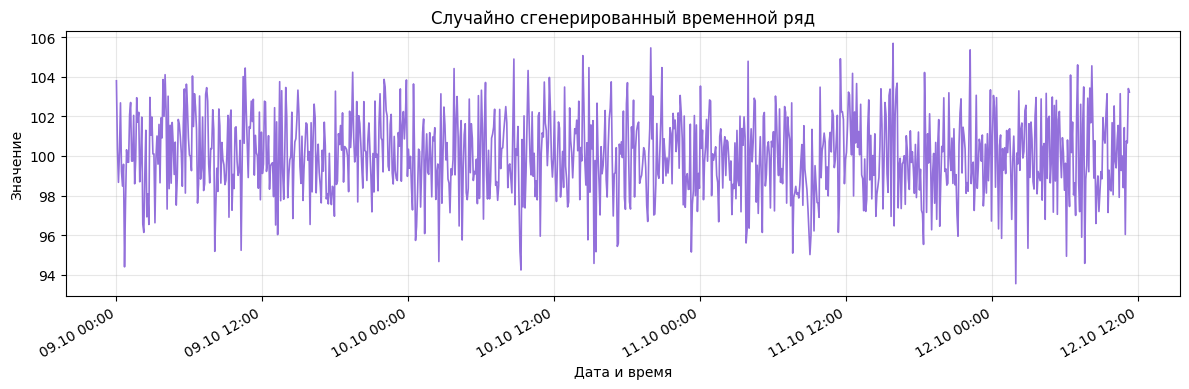

In [4]:
timestamps, values, modes = generate_time_series()
print("Количество точек:", len(values))
print("Выбранные режимы:", modes)
for timestamp, value in zip(timestamps[:3], values[:3]):
    print(timestamp.strftime("%Y-%m-%d %H:%M:%S"), f"{value:.6f}")
print("CSV:", save_csv(timestamps, values))
plot_time_series(timestamps, values, "Случайно сгенерированный временной ряд")


## 5. Три отчётных графика

Для наглядного сравнения выбраны различные комбинации параметров:

1. Постоянная дисперсия, медленный рост, без сезонности
2. Растущая дисперсия, быстрое убывание, одна сезонность с периодом **1 час**
3. Убывающая дисперсия, быстрый рост, две сезонности с периодами **1 час и 6 часов**

`seed` задан только для воспроизводимости примеров. Значения останутся случайными, но при повторном запуске с тем же `seed` будут одинаковыми.

Пример 1: {'volatility': 'const', 'trend': 'slow_up', 'seasonality': 'none'}; CSV: ts_20261009_083135_1.csv; PNG: images/lab_image_1.png


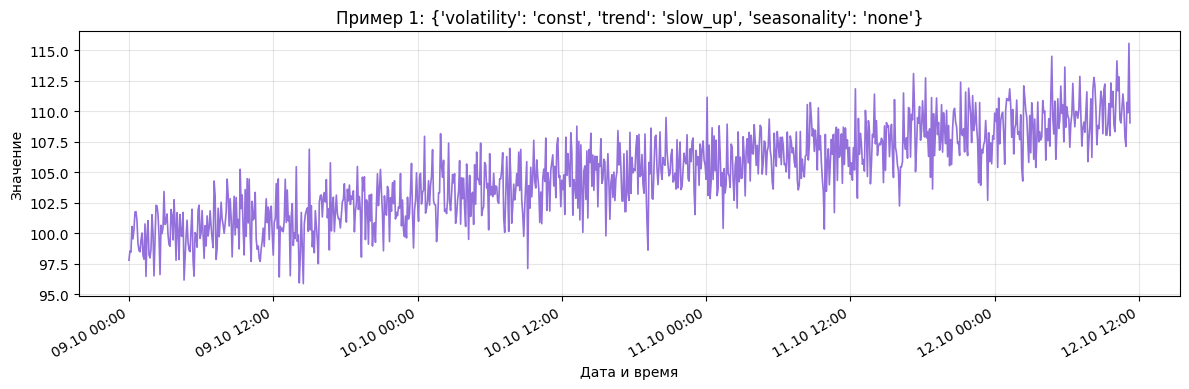

Пример 2: {'volatility': 'grow', 'trend': 'fast_down', 'seasonality': 'one'}; CSV: ts_20261009_083136.csv; PNG: images/lab_image_2.png


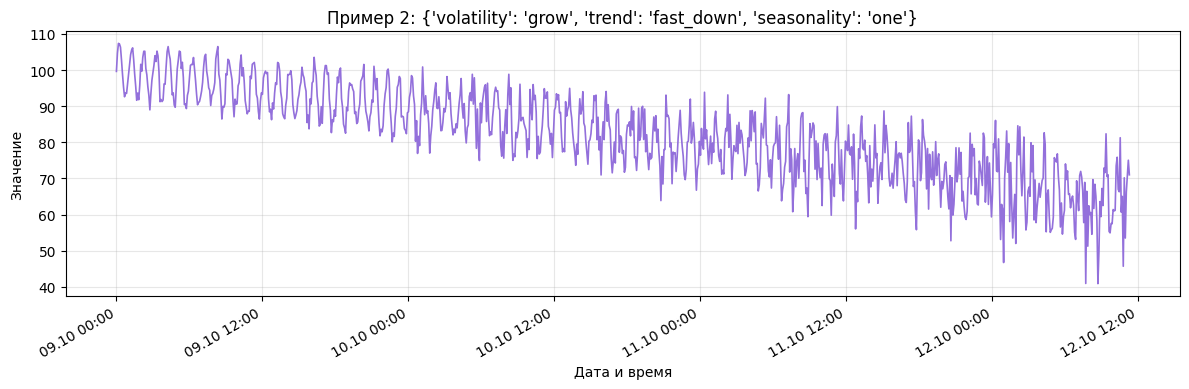

Пример 3: {'volatility': 'decay', 'trend': 'fast_up', 'seasonality': 'two'}; CSV: ts_20261009_083136_1.csv; PNG: images/lab_image_3.png


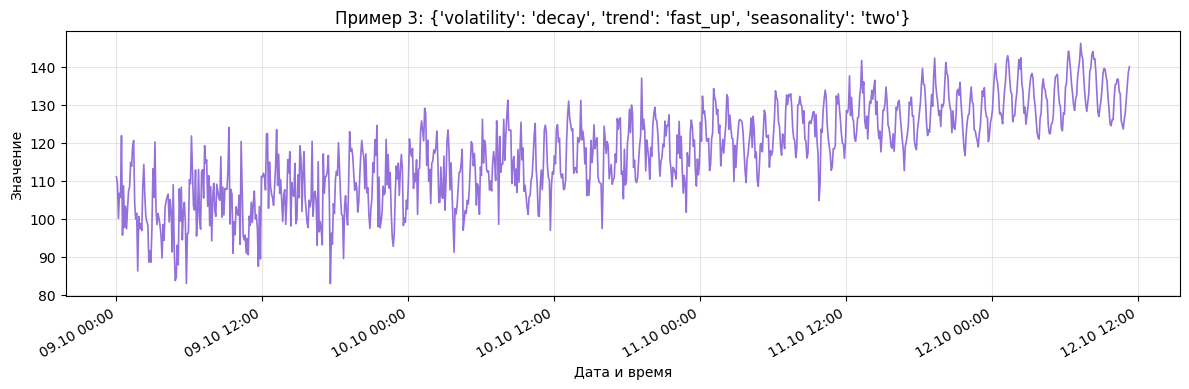

In [5]:
examples = [
    {"volatility": "const", "trend": "slow_up", "seasonality": "none", "seed": 10},
    {"volatility": "grow", "trend": "fast_down", "seasonality": "one", "seed": 20},
    {"volatility": "decay", "trend": "fast_up", "seasonality": "two", "seed": 30},
]

for number, params in enumerate(examples, start=1):
    times, series, selected = generate_time_series(n_points=1000, **params)
    png_path = IMAGE_DIR / f"lab_image_{number}.png"
    csv_path = save_csv(times, series)
    print(f"Пример {number}: {selected}; CSV: {csv_path}; PNG: {png_path}")
    plot_time_series(times, series, f"Пример {number}: {selected}", png_path)


## 6. Проверка выполнения требований

Проверяем число точек, 00:00 в начале, ровно 5 минут между соседними отсчётами, допустимые режимы и наличие созданных файлов.

In [6]:
check_times, check_values, check_modes = generate_time_series(
    n_points=1000, volatility="const", trend="none", seasonality="two", seed=42
)
assert len(check_times) == len(check_values) == 1000
assert check_times[0].hour == 0 and check_times[0].minute == 0
assert all(b - a == timedelta(minutes=5) for a, b in zip(check_times[:-1], check_times[1:]))
assert check_modes == {"volatility": "const", "trend": "none", "seasonality": "two"}
assert all((IMAGE_DIR / f"lab_image_{i}.png").is_file() for i in range(1, 4))
try:
    generate_time_series(n_points=0)
    raise AssertionError("Проверка неверного количества точек не сработала")
except ValueError:
    pass
print("Все проверки пройдены!")


Все проверки пройдены!
